# 03 – Exploratory Data Analysis (EDA)
**Parking Analytics Zurich · Person C**

**Research question:** *How do parking garage utilization patterns in Zurich differ by location, time of day, weekday/weekend and weather conditions, and how reliably can periods of high utilization be identified?*

This notebook answers the **descriptive part** of the research question and prepares the model (notebook 05). Each section is linked to a sub-question:

| Section | Sub-question | EDA method (Week 04) |
|---|---|---|
| 1. Overall picture | basis for all RQs | summary statistics, histogram |
| 2. Differences between garages | **RQ2** location | boxplot, share of time above 80/90/95 % |
| 3. Time of day and weekday | **RQ1** time | line plot, heatmap, weekday vs. weekend |
| 4. Weather | **RQ3** weather | rain vs. no rain |
| 5. Threshold and persistence | prepares **RQ4** | threshold analysis |
| 6. Answers | RQ1–RQ3, input for RQ4 | – |

**Project requirements covered here:** minimum requirement 4 (*rich non-graphical and graphical EDA*). The threshold analysis in section 5 prepares requirements 5–7 (model, evaluation, interpretation) in notebook 05.

> **Data:** B's cleaned data (`occupancy_clean`, notebook 02) with the real capacities, joined with the garage master data and A's hourly weather. `load_data()` in `src/analysis_prep.py` reads it from PostgreSQL with `sql/queries/c_analysis_dataset.sql` (joins), or from the CSV files when no database connection is configured. Both give the same data. Nothing is re-cleaned here.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.analysis_prep import load_data, caption

FIG_DIR = Path.cwd().parent / "figures" / "analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)

CAPTION = ""   # set below once the data is loaded

def save(fig, name):
    # Every figure carries its source, period and sample size (scientific standard)
    fig.tight_layout(); fig.text(0.01, 0, CAPTION, ha="left", va="top", fontsize=8, color="#555555")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)

## Data basis

In [2]:
df = load_data()
CAPTION = caption(df)
df.head()

PostgreSQL not reachable (OperationalError: connection is bad: connection to server on socket "/tmp/.s.PGSQL.5433" failed: No such file or directory
	Is the server running locally and accepting connections on that socket?) – falling back to the CSV files.


Data source: CSV files (data/processed, data/raw)
57,742 rows · 33 garages · 20.10.2026 – 09.11.2026 · weather missing for 4.8% of rows


,slot_utc,parking_id,parking_name,free_spaces,capacity_used,occupancy_rate,is_weekend,latitude,longitude,temperature_c,precipitation_mm,slot_local,date,hour,minute_of_day,weekday,weekday_name,is_rain
0,2026-10-20 10:00:00+00:00,accu,Accu,171.0,213.0,0.197,0,47.415,8.541,12.4,0.0,2026-10-20 12:00:00+02:00,2026-10-20,12,720,1,Tue,0
1,2026-10-20 10:45:00+00:00,accu,Accu,171.0,213.0,0.197,0,47.415,8.541,12.4,0.0,2026-10-20 12:45:00+02:00,2026-10-20,12,765,1,Tue,0
2,2026-10-20 14:15:00+00:00,accu,Accu,172.0,213.0,0.192,0,47.415,8.541,13.8,0.0,2026-10-20 16:15:00+02:00,2026-10-20,16,975,1,Tue,0
3,2026-10-20 15:30:00+00:00,accu,Accu,171.0,213.0,0.197,0,47.415,8.541,13.7,0.0,2026-10-20 17:30:00+02:00,2026-10-20,17,1050,1,Tue,0
4,2026-10-20 19:30:00+00:00,accu,Accu,168.0,213.0,0.211,0,47.415,8.541,11.0,0.0,2026-10-20 21:30:00+02:00,2026-10-20,21,1290,1,Tue,0


**How many days does each weekday cover?** Averages per weekday are only as reliable as the number of days behind them. Differences *between individual weekdays* should only be interpreted with several days per weekday. This table updates automatically on every run.

In [3]:
days_per_weekday = (df.groupby(["weekday", "weekday_name", "date"]).size()
                      .loc[lambda s: s >= 0.5 * df.parking_id.nunique() * 96]   # at least half a day of data
                      .reset_index().groupby(["weekday", "weekday_name"]).date.nunique()
                      .droplevel(0).rename("full days"))
days_per_weekday.to_frame().T

weekday_name,Mon,Tue,Wed,Thu,Fri,Sat,Sun
full days,3,2,2,2,3,3,3


## 1. Overall picture: how busy are Zurich's garages?

In [4]:
summary = (df.groupby("parking_name")
             .agg(n=("occupancy_rate", "size"),
                  capacity=("capacity_used", "first"),
                  mean=("occupancy_rate", "mean"),
                  median=("occupancy_rate", "median"),
                  std=("occupancy_rate", "std"),
                  peak=("occupancy_rate", "max"),
                  share_ge_85=("occupancy_rate", lambda s: (s >= 0.85).mean()),
                  share_ge_90=("occupancy_rate", lambda s: (s >= 0.90).mean()))
             .sort_values("mean", ascending=False))
summary.style.format({"capacity": "{:.0f}", "mean": "{:.1%}", "median": "{:.1%}", "std": "{:.1%}",
                      "peak": "{:.1%}", "share_ge_85": "{:.1%}", "share_ge_90": "{:.1%}"})

,n,capacity,mean,median,std,peak,share_ge_85,share_ge_90
parking_name,,,,,,,,
Zürichhorn,1750,195,79.0%,78.5%,4.4%,97.4%,12.3%,0.7%
Crowne Plaza,1748,310,76.6%,78.1%,12.6%,100.0%,28.4%,16.3%
Utoquai,1750,153,71.3%,71.9%,17.5%,100.0%,26.2%,20.3%
Talgarten,1750,110,70.4%,75.5%,25.2%,100.0%,41.7%,36.3%
Bleicherweg,1750,258,60.0%,56.6%,21.7%,100.0%,17.7%,12.1%
USZ Süd,1750,80,54.6%,45.0%,29.1%,100.0%,24.9%,23.1%
Jelmoli,1750,227,54.2%,48.9%,27.4%,100.0%,21.8%,18.0%
Globus,1750,139,50.8%,46.0%,35.7%,100.0%,29.1%,26.2%
Urania,1750,481,48.8%,43.0%,33.6%,100.0%,22.7%,18.5%


In [5]:
overall = df.occupancy_rate.describe()
print("All garages together:")
print(f"  mean {overall['mean']:.1%}, median {overall['50%']:.1%}, std {overall['std']:.1%}")
print(f"  skewness {df.occupancy_rate.skew():.2f}")

All garages together:
  mean 41.3%, median 33.8%, std 29.0%
  skewness 0.54


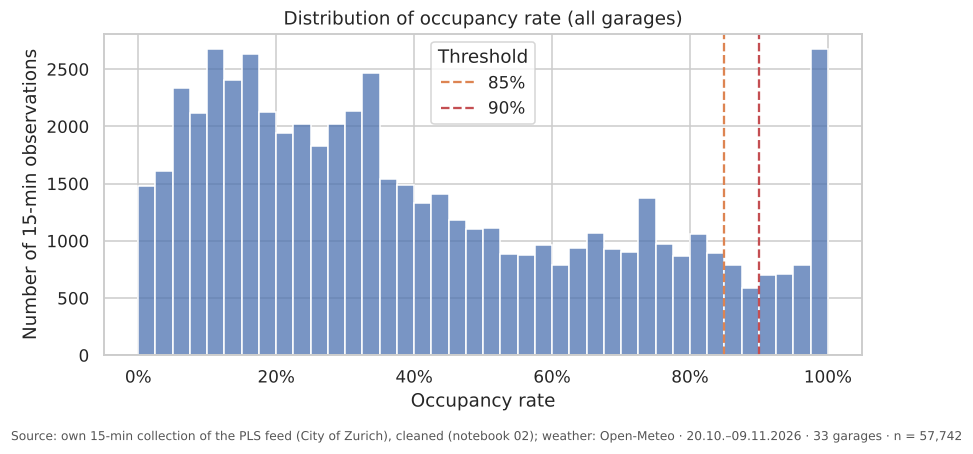

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df.occupancy_rate, bins=40, ax=ax, color="#4C72B0")
for t, c in [(0.85, "#DD8452"), (0.90, "#C44E52")]:
    ax.axvline(t, color=c, ls="--", lw=1.5, label=f"{t:.0%}")
ax.set(xlabel="Occupancy rate", ylabel="Number of 15-min observations",
       title="Distribution of occupancy rate (all garages)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(title="Threshold")
save(fig, "eda_histogram")
plt.show()

## 2. RQ2 – Differences between garages (location)

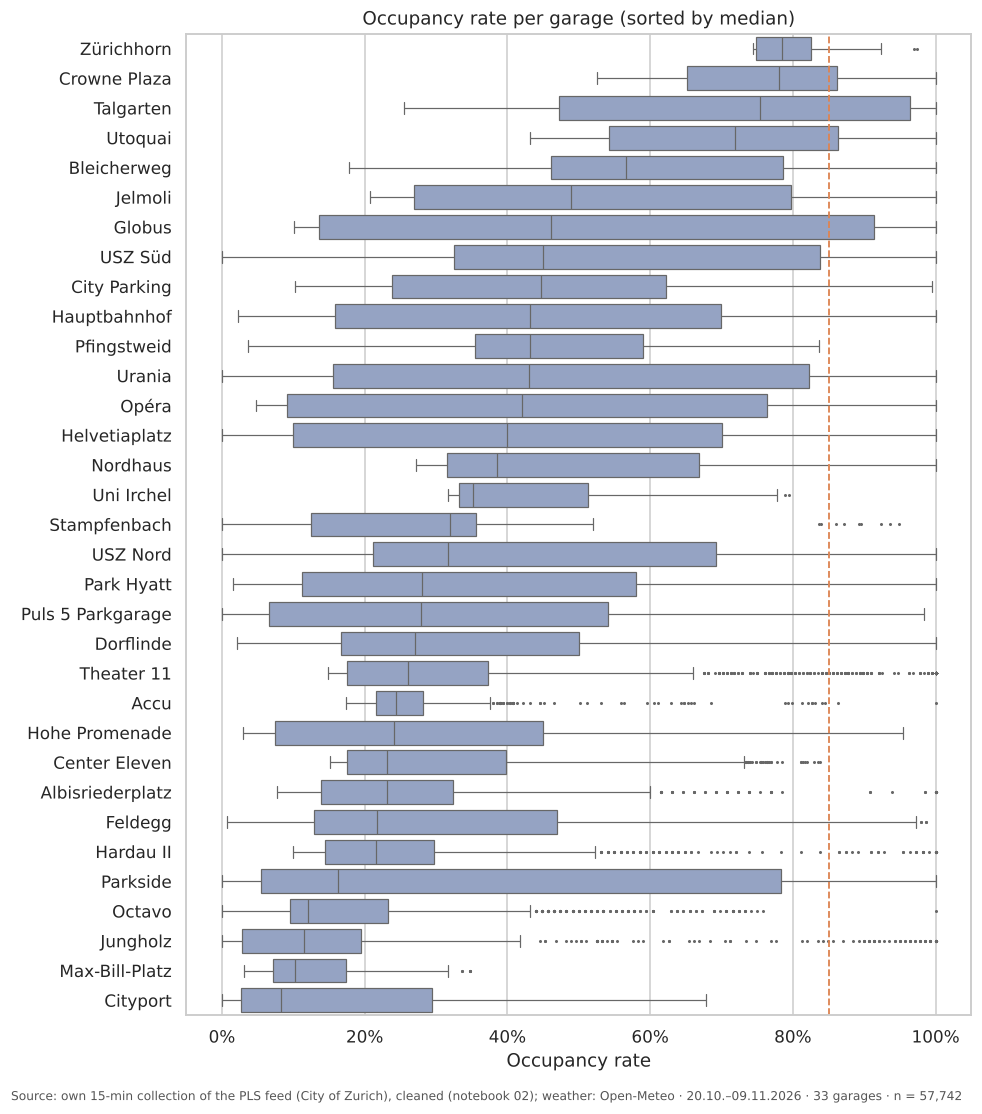

In [7]:
order = df.groupby("parking_name").occupancy_rate.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 10))
sns.boxplot(data=df, y="parking_name", x="occupancy_rate", order=order, ax=ax,
            color="#8DA0CB", fliersize=1, linewidth=0.8)
ax.axvline(0.85, color="#DD8452", ls="--", lw=1.2)
ax.set(xlabel="Occupancy rate", ylabel="", title="Occupancy rate per garage (sorted by median)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
save(fig, "eda_boxplot_per_garage")
plt.show()

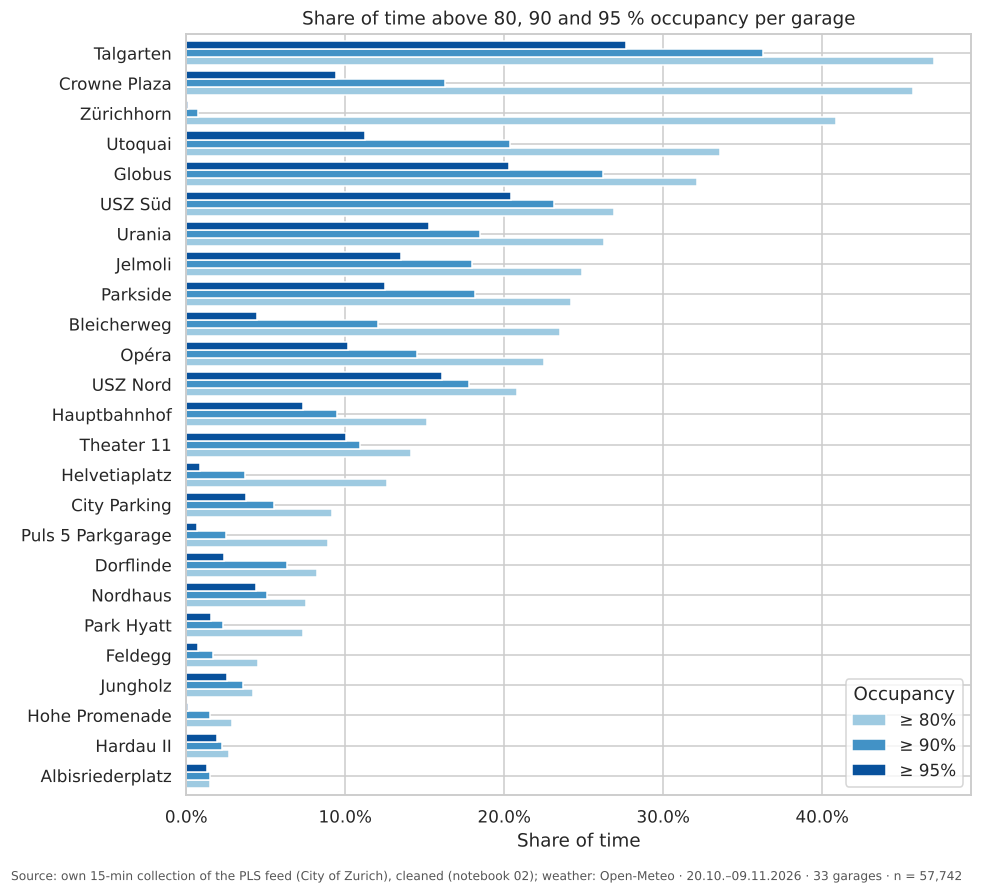

Garages shown: 25 of 33; the others are almost never above 80 %.


In [8]:
share = pd.DataFrame({f"≥ {t:.0%}": (df.occupancy_rate >= t).groupby(df.parking_name).mean()
                      for t in [0.80, 0.90, 0.95]}).sort_values("≥ 80%")
share = share[share["≥ 80%"] >= 0.01]   # garages that reach 80 % at least 1 % of the time
fig, ax = plt.subplots(figsize=(9, 8))
share.plot.barh(ax=ax, width=0.8, color=["#9ECAE1", "#4292C6", "#08519C"])
ax.set(xlabel="Share of time", ylabel="", title="Share of time above 80, 90 and 95 % occupancy per garage")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(title="Occupancy", loc="lower right")
save(fig, "eda_share_above_thresholds")
plt.show()
print(f"Garages shown: {len(share)} of {df.parking_name.nunique()}; the others are almost never above 80 %.")

## 3. RQ1 – Time of day and weekday

### 3.1 One day in detail

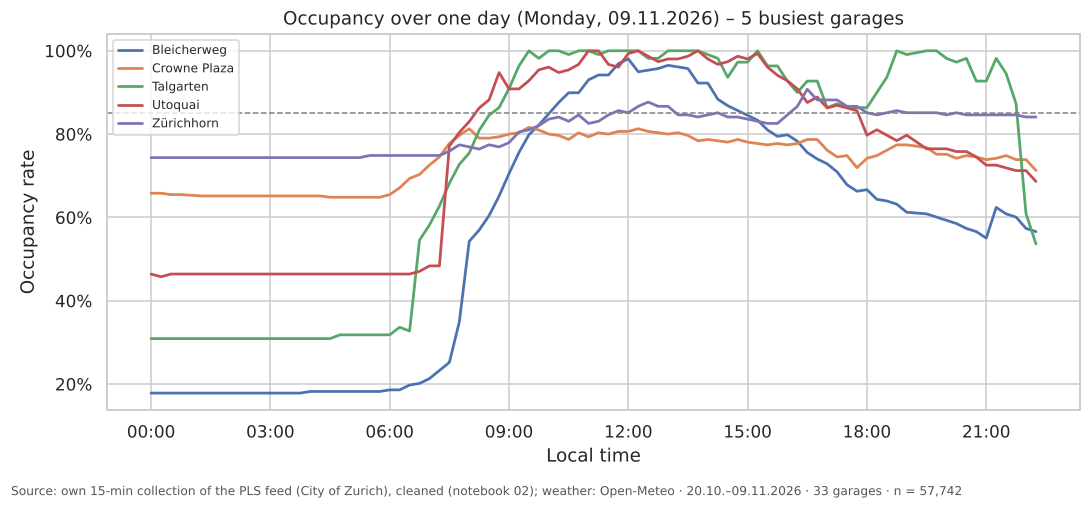

In [9]:
# Pick the most recent weekday with the best coverage and the 5 busiest garages
coverage = df[df.is_weekend == 0].groupby("date").size()
day = coverage[coverage >= coverage.max() * 0.9].index.max()
top5 = summary.index[:5]
d = df[(df.date == day) & (df.parking_name.isin(top5))]

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=d, x="slot_local", y="occupancy_rate", hue="parking_name", ax=ax, lw=1.8)
ax.axhline(0.85, color="grey", ls="--", lw=1)
ax.set(xlabel="Local time", ylabel="Occupancy rate",
       title=f"Occupancy over one day ({pd.Timestamp(day):%A, %d.%m.%Y}) – 5 busiest garages")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz="Europe/Zurich"))
ax.legend(title="", fontsize=8, loc="upper left")
save(fig, "eda_line_one_day")
plt.show()

### 3.2 Heatmap: weekday × hour

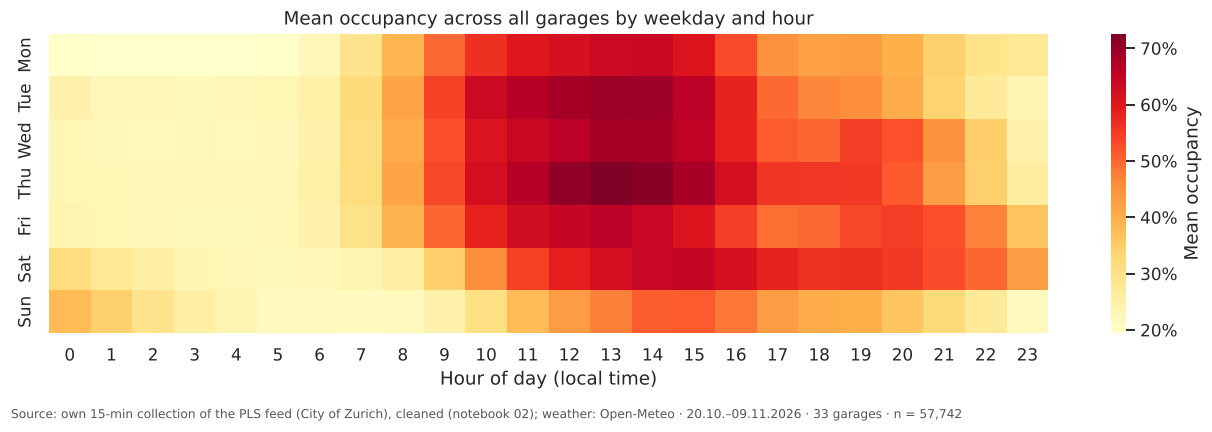

In [10]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat = df.pivot_table(index="weekday_name", columns="hour", values="occupancy_rate", aggfunc="mean").reindex(days)
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Mean occupancy", "format": plt.matplotlib.ticker.PercentFormatter(1)})
ax.set(xlabel="Hour of day (local time)", ylabel="", title="Mean occupancy across all garages by weekday and hour")
save(fig, "eda_heatmap_weekday_hour")
plt.show()

### 3.3 Weekday vs. weekend

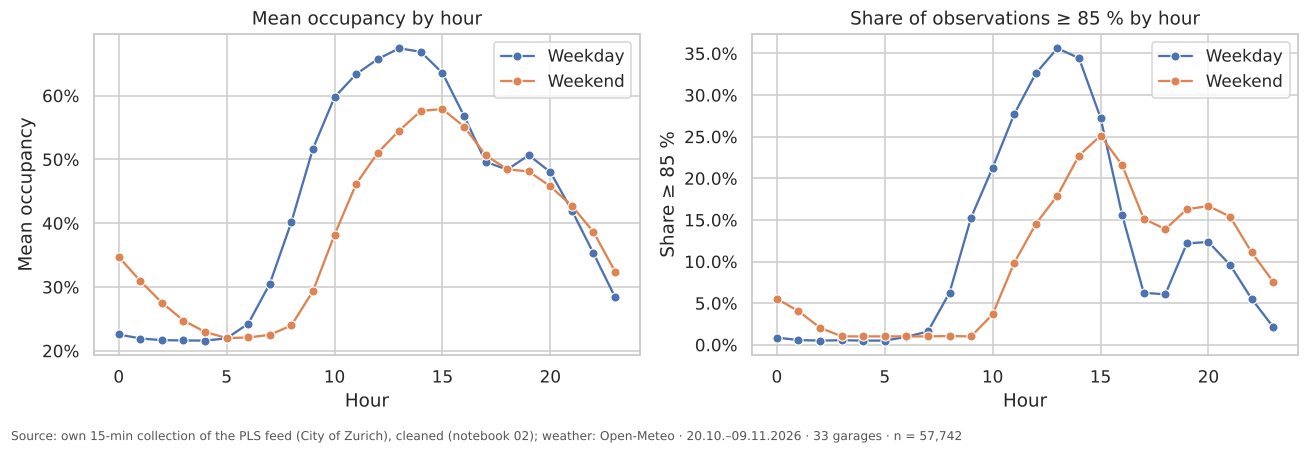

,mean,median,share_ge_85
Weekday,42.6%,35.2%,11.5%
Weekend,38.6%,32.4%,9.6%


In [11]:
prof = (df.assign(day_type=np.where(df.is_weekend == 1, "Weekend", "Weekday"))
          .groupby(["day_type", "hour"]).occupancy_rate.agg(["mean", lambda s: (s >= 0.85).mean()])
          .rename(columns={"<lambda_0>": "share_ge_85"}).reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=prof, x="hour", y="mean", hue="day_type", ax=axes[0], marker="o")
axes[0].set(title="Mean occupancy by hour", xlabel="Hour", ylabel="Mean occupancy")
sns.lineplot(data=prof, x="hour", y="share_ge_85", hue="day_type", ax=axes[1], marker="o")
axes[1].set(title="Share of observations ≥ 85 % by hour", xlabel="Hour", ylabel="Share ≥ 85 %")
for a in axes:
    a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); a.legend(title="")
save(fig, "eda_weekday_vs_weekend")
plt.show()

wk = df.groupby("is_weekend").occupancy_rate.agg(["mean", "median", lambda s: (s >= .85).mean()])
wk.index = ["Weekday", "Weekend"]; wk.columns = ["mean", "median", "share_ge_85"]
wk.style.format("{:.1%}")

### 3.4 Contingency table: day type × high utilization (non-graphical, multivariate)
Counts and row percentages of observations at or above 85 %. B tests this relationship formally with a chi-squared test (notebook 04); here it is only described.

In [12]:
ct = pd.crosstab(np.where(df.is_weekend == 1, "Weekend", "Weekday"),
                 np.where(df.occupancy_rate >= 0.85, "high (≥ 85 %)", "not high"),
                 margins=True, margins_name="Total")
ct_pct = pd.crosstab(np.where(df.is_weekend == 1, "Weekend", "Weekday"),
                     np.where(df.occupancy_rate >= 0.85, "high (≥ 85 %)", "not high"), normalize="index")
display(ct)
ct_pct.style.format("{:.1%}")

col_0,high (≥ 85 %),not high,Total
row_0,,,
Weekday,4434,34234,38668
Weekend,1824,17250,19074
Total,6258,51484,57742


col_0,high (≥ 85 %),not high
row_0,,
Weekday,11.5%,88.5%
Weekend,9.6%,90.4%


## 4. RQ3 – Weather: rain vs. no rain
Weather and time of day are linked (it rains at some hours more than at others). A plain average of "rain" vs. "no rain" would therefore partly compare different hours. We compare **within the same hour and day type** instead. An hour counts as rain from 0.1 mm precipitation.

Rows with weather: 54,970 · rain hours: 9.4% of all 15-min slots


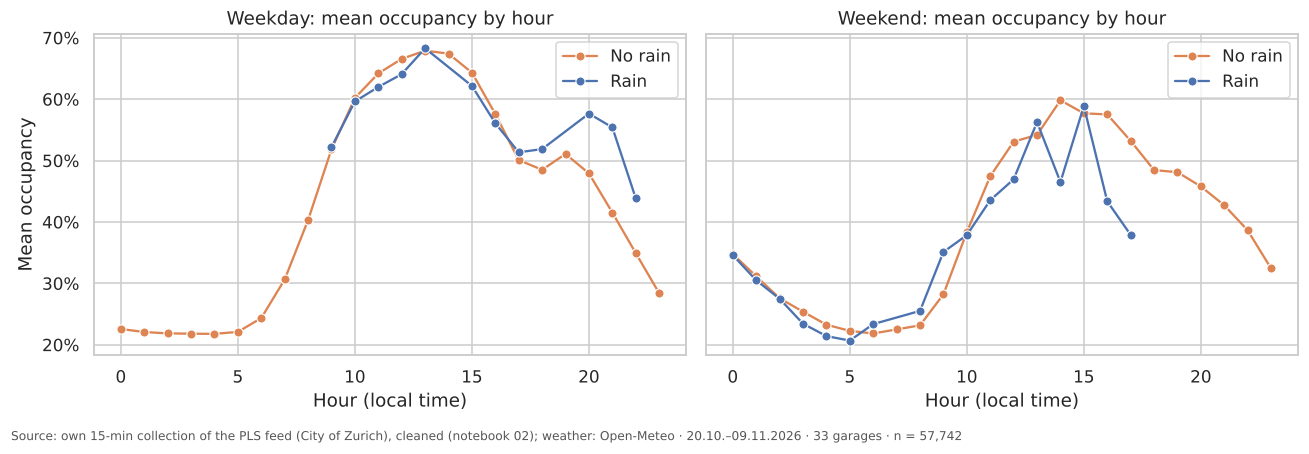

In [13]:
dw = df.dropna(subset=["is_rain"]).assign(
    weather=lambda d: np.where(d.is_rain == 1, "Rain", "No rain"),
    day_type=lambda d: np.where(d.is_weekend == 1, "Weekend", "Weekday"))
print(f"Rows with weather: {len(dw):,} · rain hours: {dw.drop_duplicates('slot_utc').is_rain.mean():.1%} of all 15-min slots")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, dt in zip(axes, ["Weekday", "Weekend"]):
    sns.lineplot(data=dw[dw.day_type == dt], x="hour", y="occupancy_rate", hue="weather", hue_order=["No rain", "Rain"],
                 palette=["#DD8452", "#4C72B0"], ax=ax, errorbar=None, marker="o")
    ax.set(title=f"{dt}: mean occupancy by hour", xlabel="Hour (local time)", ylabel="Mean occupancy")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.legend(title="")
save(fig, "eda_rain_vs_no_rain")
plt.show()

Non-graphical: daytime only (08:00–19:59), where most parking happens.

In [14]:
day = dw[dw.hour.between(8, 19)]
rain_tab = (day.groupby(["day_type", "weather"]).occupancy_rate
               .agg(n="size", mean="mean", median="median", share_ge_85=lambda s: (s >= .85).mean())
               .unstack("weather"))
rain_tab.style.format({c: "{:,.0f}" if c[0] == "n" else "{:.1%}" for c in rain_tab.columns})

In [15]:
# Same comparison hour by hour, then averaged: removes the time-of-day effect
by_hour = day.groupby(["day_type", "hour", "weather"]).occupancy_rate.mean().unstack("weather")
by_hour["difference (rain − no rain)"] = by_hour["Rain"] - by_hour["No rain"]
diff = by_hour.groupby("day_type")["difference (rain − no rain)"].agg(["mean", "min", "max"])
print("Difference in mean occupancy, rain minus no rain, within the same hour (percentage points):")
(diff * 100).round(1)

Difference in mean occupancy, rain minus no rain, within the same hour (percentage points):


,mean,min,max
day_type,,,
Weekday,-0.4,-2.5,3.4
Weekend,-4.1,-15.3,6.9


## 5. Preparing RQ4: threshold for *high utilization*

The model will predict whether a garage is *highly utilized* in 30 minutes. The threshold must be:
- **meaningful** for drivers (the garage is close to full), and
- **frequent enough** that a classifier has enough positive examples.

In [16]:
thresholds = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
rows = []
for t in thresholds:
    high = df.occupancy_rate >= t
    per_garage = high.groupby(df.parking_id).mean()
    rows.append({"threshold": t,
                 "share_of_observations": high.mean(),
                 "garages_ever_above": int((per_garage > 0).sum()),
                 "garages_above_5pct_of_time": int((per_garage >= 0.05).sum())})
thr = pd.DataFrame(rows).set_index("threshold")
thr.style.format({"share_of_observations": "{:.1%}"})

,share_of_observations,garages_ever_above,garages_above_5pct_of_time
threshold,,,
0.700000,21.4%,31,22
0.750000,17.4%,31,21
0.800000,14.2%,30,20
0.850000,10.8%,28,18
0.900000,8.4%,28,16
0.950000,6.0%,27,12


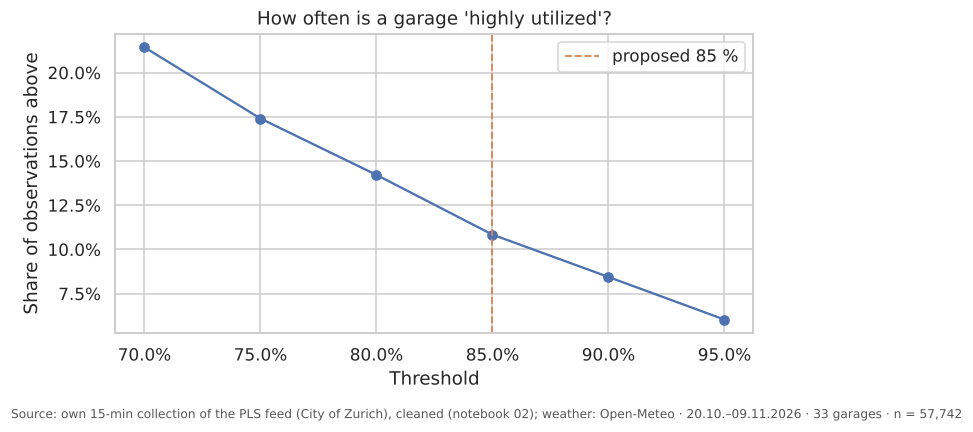

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thr.index, thr.share_of_observations, marker="o", color="#4C72B0")
ax.axvline(0.85, color="#DD8452", ls="--", lw=1.2, label="proposed 85 %")
ax.set(xlabel="Threshold", ylabel="Share of observations above",
       title="How often is a garage 'highly utilized'?")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend()
save(fig, "eda_threshold_curve")
plt.show()

### 5.1 How persistent is high utilization?
If high utilization usually lasts for hours, simply copying the current state ("persistence") is already a strong forecast. The interesting cases for the model are the **transitions**: garages that are *not yet* above the threshold but will be in 30 minutes.

In [18]:
s = df[["parking_id", "slot_utc", "occupancy_rate"]]
fut = s.assign(slot_utc=s.slot_utc - pd.Timedelta("30min")).rename(columns={"occupancy_rate": "occ_30"})
pair = s.merge(fut, on=["parking_id", "slot_utc"], how="inner")
rows = []
for t in [0.80, 0.85, 0.90]:
    now, later = pair.occupancy_rate >= t, pair.occ_30 >= t
    rows.append({"threshold": t,
                 "P(high in 30 min | high now)": later[now].mean(),
                 "P(high in 30 min | not high now)": later[~now].mean(),
                 "new episodes (transitions)": int((later & ~now).sum()),
                 "positives in 30 min": int(later.sum())})
persist = pd.DataFrame(rows).set_index("threshold")
print(f"Pairs (t, t+30 min) available: {len(pair):,}")
persist.style.format({"P(high in 30 min | high now)": "{:.1%}", "P(high in 30 min | not high now)": "{:.2%}"})

Pairs (t, t+30 min) available: 56,844


,P(high in 30 min | high now),P(high in 30 min | not high now),new episodes (transitions),positives in 30 min
threshold,,,,
0.800000,90.5%,1.55%,756,8047
0.850000,88.6%,1.37%,696,6137
0.900000,86.9%,1.21%,631,4792


## 6. Answers to the research questions (so far)

In [19]:
# Numbers used in the findings below (recomputed on every run)
peak_hour_wd = prof[prof.day_type == "Weekday"].set_index("hour")["mean"].idxmax()
peak_hour_we = prof[prof.day_type == "Weekend"].set_index("hour")["mean"].idxmax()
print(f"Busiest garages (mean): {', '.join(summary.index[:3])}")
print(f"Quietest garages (mean): {', '.join(summary.index[-3:])}")
print(f"Peak hour weekday: {peak_hour_wd}:00, weekend: {peak_hour_we}:00")
print(f"Share >= 85 %: {(df.occupancy_rate >= .85).mean():.1%}; >= 90 %: {(df.occupancy_rate >= .90).mean():.1%}")
print(f"Persistence at 85 %: {persist.loc[0.85, 'P(high in 30 min | high now)']:.1%}")

Busiest garages (mean): Zürichhorn, Crowne Plaza, Utoquai
Quietest garages (mean): Cityport, Jungholz, Max-Bill-Platz
Peak hour weekday: 13:00, weekend: 15:00
Share >= 85 %: 10.8%; >= 90 %: 8.4%
Persistence at 85 %: 88.6%


*Status: B's cleaned data from 20 Oct to 9 Nov 2026 (2–3 full days per weekday), 33 garages, real capacities, weather until 8 Nov. Re-run after the final cut-off date; the numbers in this cell are taken from the outputs above and must then be checked again.*

**RQ1 – Time of day and weekday:** Occupancy follows a clear daily rhythm. On weekdays, the mean across all garages rises from about 22 % at night to 67 % at 13:00. At weekends, the peak is lower (58 %) and later (15:00); Saturday stays busy into the evening, and Sunday is the quietest day (mean 34 % vs. 39–45 % on the other days). 11.5 % of weekday observations are at or above 85 %, compared with 9.6 % at weekends (contingency table 3.4; B tests whether this difference is significant).

**RQ2 – Location:** Differences between garages are larger than differences over time. Garages in the city centre and along the lake (Zürichhorn, Crowne Plaza, Utoquai, Talgarten) are on average 70–79 % full, and Talgarten and Crowne Plaza are at or above 80 % for almost half of the time. Garages in Oerlikon and the outer districts (Max-Bill-Platz, Jungholz, Cityport, Octavo) average only 12–19 %; 8 of 33 garages almost never reach 80 %. B's map and k-means clustering show where these groups are. **Caveat for B:** at several of the busiest garages the feed never reports more than a fraction of the city's capacity as free (Zürichhorn at most 50 of 195, Crowne Plaza 147 of 310, Utoquai 87 of 153, Talgarten 82 of 110). Possibly only part of the spaces is in the guidance system, so their occupancy may be overestimated.

**RQ3 – Weather:** Weather has only a small effect. Within the same hour, rain changes the mean occupancy by −0.4 percentage points on weekdays and by −4.1 points at weekends (daytime 08:00–19:59). Caveat: only 9 % of the slots had rain, and the period covers few days, so these differences are uncertain.

**Input for RQ4 – Prediction:**
- *High utilization* is defined as **≥ 85 %**: 10.8 % of all observations, enough positive cases for a classifier, and still meaningful for drivers ("almost full"). At 95 % only 6.0 % would be positive.
- High utilization is persistent: a garage at or above 85 % is still there 30 minutes later in about 89 % of cases. A model therefore has to beat the simple rule "stays as it is now". Its real value lies in predicting garages that are **about to become full**.
